In [1]:
import os, csv, random, tarfile, urllib.request
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn.functional as F
from torchvision import models
from torchvision.datasets import ImageFolder

%pip -q install grad-cam
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)
random.seed(42)
np.random.seed(42)
torch.manual_seed(42)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Device: cpu


In [2]:
url = 'https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-160.tgz'
archive = Path('/content/imagenette2-160.tgz')
root = Path('/content/imagenette2-160')
if not (root / 'val').exists():
    if not archive.exists():
        print('Downloading ImageNette...')
        urllib.request.urlretrieve(url, archive)
    print('Extracting ImageNette...')
    with tarfile.open(archive, 'r:gz') as tar:
        for member in tar.getmembers():
            target = (Path('/content') / member.name).resolve()
            if not str(target).startswith('/content/imagenette2-160/') and target != root:
                raise ValueError('Unexpected archive path: ' + member.name)
            if member.issym() or member.islnk():
                raise ValueError('Unexpected link in archive')
        tar.extractall('/content')
dataset = ImageFolder(root / 'val')
print('Validation images:', len(dataset))
print('Folder labels:', dataset.classes)
examples = []
for class_idx in range(len(dataset.classes)):
    matches = [path for path, label in dataset.samples if label == class_idx]
    examples.append(Path(random.choice(matches)))
print('Selected', len(examples), 'images')

Extracting ImageNette...


/tmp/ipykernel_712/1106955107.py:16: DeprecationWarning: Python 3.14 will, by default, filter extracted tar archives and reject files or modify their metadata. Use the filter argument to control this behavior.
  tar.extractall('/content')


Validation images: 3925
Folder labels: ['n01440764', 'n02102040', 'n02979186', 'n03000684', 'n03028079', 'n03394916', 'n03417042', 'n03425413', 'n03445777', 'n03888257']
Selected 10 images


In [3]:
resnet_weights = models.ResNet18_Weights.DEFAULT
vit_weights = models.ViT_B_16_Weights.DEFAULT
resnet = models.resnet18(weights=resnet_weights).to(device).eval()
vit = models.vit_b_16(weights=vit_weights).to(device).eval()
resnet_preprocess = resnet_weights.transforms()
vit_preprocess = vit_weights.transforms()
resnet_labels = resnet_weights.meta['categories']
vit_labels = vit_weights.meta['categories']

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 139MB/s]


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:03<00:00, 95.0MB/s]


**ResNet-18 Grad-CAM**

In [4]:
def resnet_gradcam(pil_image):
    tensor = resnet_preprocess(pil_image).unsqueeze(0).to(device)
    with torch.no_grad():
        scores = resnet(tensor)
        probs = torch.softmax(scores, dim=1)[0]
        idx = int(probs.argmax().item())
        confidence = float(probs[idx].item())

    with GradCAM(model=resnet, target_layers=[resnet.layer4[-1]]) as cam:
        heatmap = cam(input_tensor=tensor, targets=None)[0]

    rgb = np.asarray(pil_image.convert('RGB').resize((224, 224)), dtype=np.float32) / 255.0
    overlay = show_cam_on_image(rgb, heatmap, use_rgb=True)
    return resnet_labels[idx], confidence, overlay

**ViT Attention Rollout**

In [5]:
def vit_attention_rollout(pil_image):
    tensor = vit_preprocess(pil_image).unsqueeze(0).to(device)
    captured = []
    hooks = []

    def make_hook(attn_module):
        def capture(module, inputs):
            x = inputs[0].detach()
            d = x.shape[-1]
            num_heads = module.num_heads
            head_dim = d // num_heads
            qkv = F.linear(x, module.in_proj_weight, module.in_proj_bias)
            q, k, _ = qkv.chunk(3, dim=-1)
            q = q.reshape(1, -1, num_heads, head_dim).transpose(1, 2)
            k = k.reshape(1, -1, num_heads, head_dim).transpose(1, 2)
            attn = (q @ k.transpose(-2, -1)) * (head_dim ** -0.5)
            attn = attn.softmax(dim=-1).mean(dim=1)[0]  # [tokens, tokens]
            captured.append(attn.cpu())
        return capture

    for block in vit.encoder.layers:
        hooks.append(block.self_attention.register_forward_pre_hook(make_hook(block)))
    try:
        with torch.no_grad():
            scores = vit(tensor)
    finally:
        for hook in hooks:
            hook.remove()

    probs = scores.softmax(dim=1)[0]
    idx = int(probs.argmax().item())
    confidence = float(probs[idx].item())
    assert len(captured) == len(vit.encoder.layers), 'Not all attention layers were captured'

    tokens = captured[0].shape[0]
    rollout = torch.eye(tokens)
    for attention in captured:
        attention = attention + torch.eye(tokens)
        attention = attention / attention.sum(dim=-1, keepdim=True)
        rollout = attention @ rollout

    patch_scores = rollout[0, 1:]
    grid_side = int(np.sqrt(patch_scores.numel()))
    assert grid_side ** 2 == patch_scores.numel()
    heatmap = patch_scores.reshape(grid_side, grid_side).numpy()
    heatmap -= heatmap.min()
    heatmap /= heatmap.max() + 1e-8
    heatmap_img = Image.fromarray(np.uint8(heatmap * 255)).resize((224, 224), Image.Resampling.BILINEAR)
    heatmap = np.asarray(heatmap_img, dtype=np.float32) / 255.0
    rgb = np.asarray(pil_image.convert('RGB').resize((224, 224)), dtype=np.float32) / 255.0
    overlay = show_cam_on_image(rgb, heatmap, use_rgb=True)
    return vit_labels[idx], confidence, overlay

GRAD-CAM VS VISION TRANSFORMER RESULTS

IMAGE 1 OF 10
ImageNette category: Tench
ResNet prediction: tench
ResNet confidence: 73.3%
ViT prediction: tench
ViT confidence: 82.5%


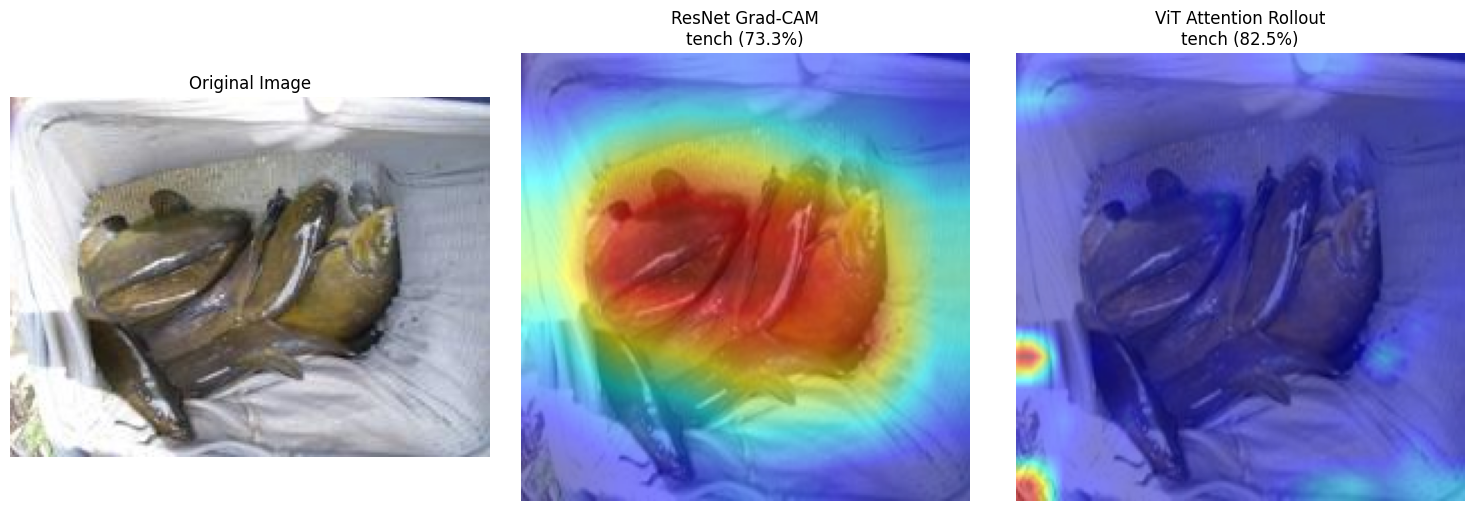


IMAGE 2 OF 10
ImageNette category: English Springer
ResNet prediction: Cardigan
ResNet confidence: 30.1%
ViT prediction: English springer
ViT confidence: 62.6%


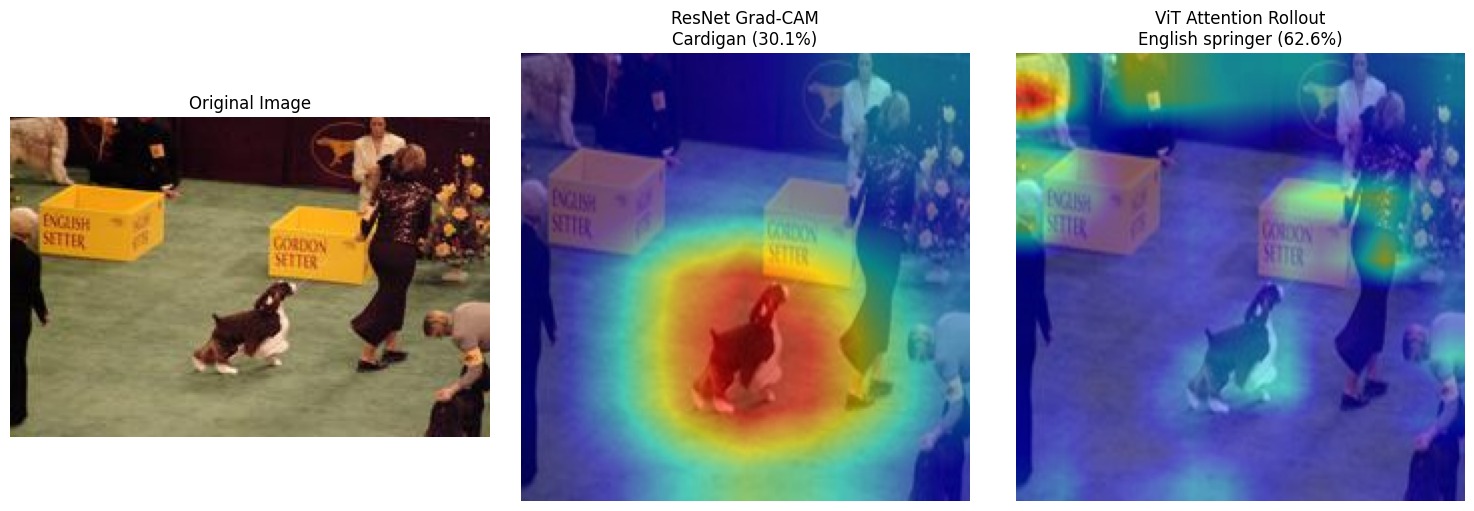


IMAGE 3 OF 10
ImageNette category: Cassette Player
ResNet prediction: tape player
ResNet confidence: 37.3%
ViT prediction: CD player
ViT confidence: 36.2%


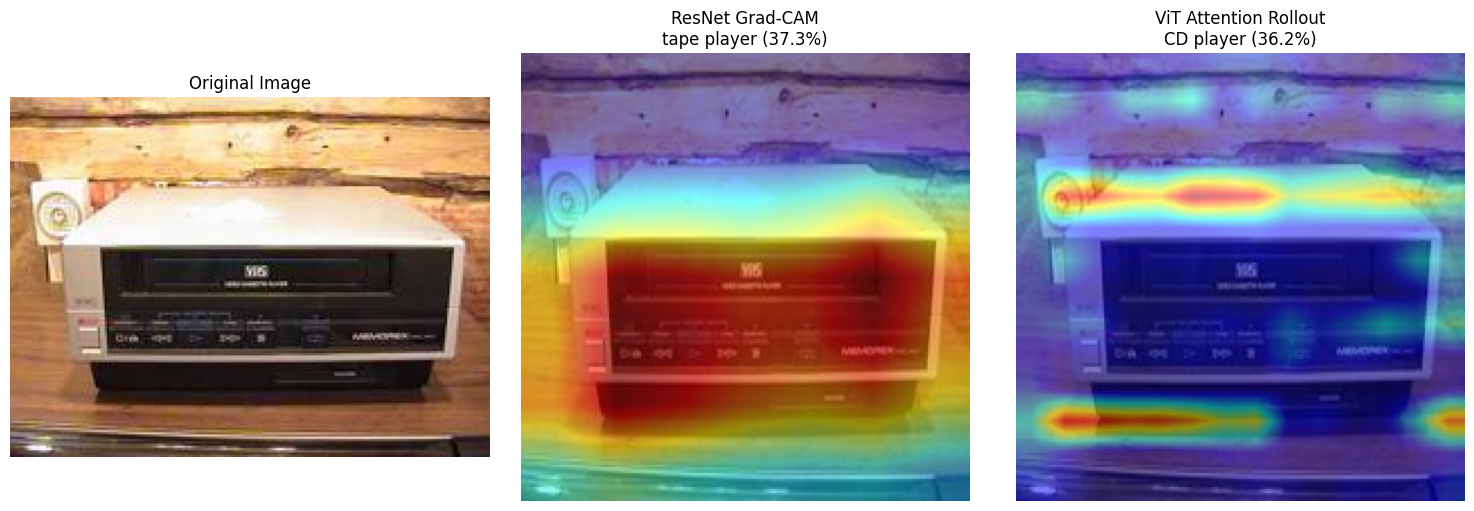


IMAGE 4 OF 10
ImageNette category: Chain Saw
ResNet prediction: chain saw
ResNet confidence: 24.9%
ViT prediction: chain saw
ViT confidence: 89.6%


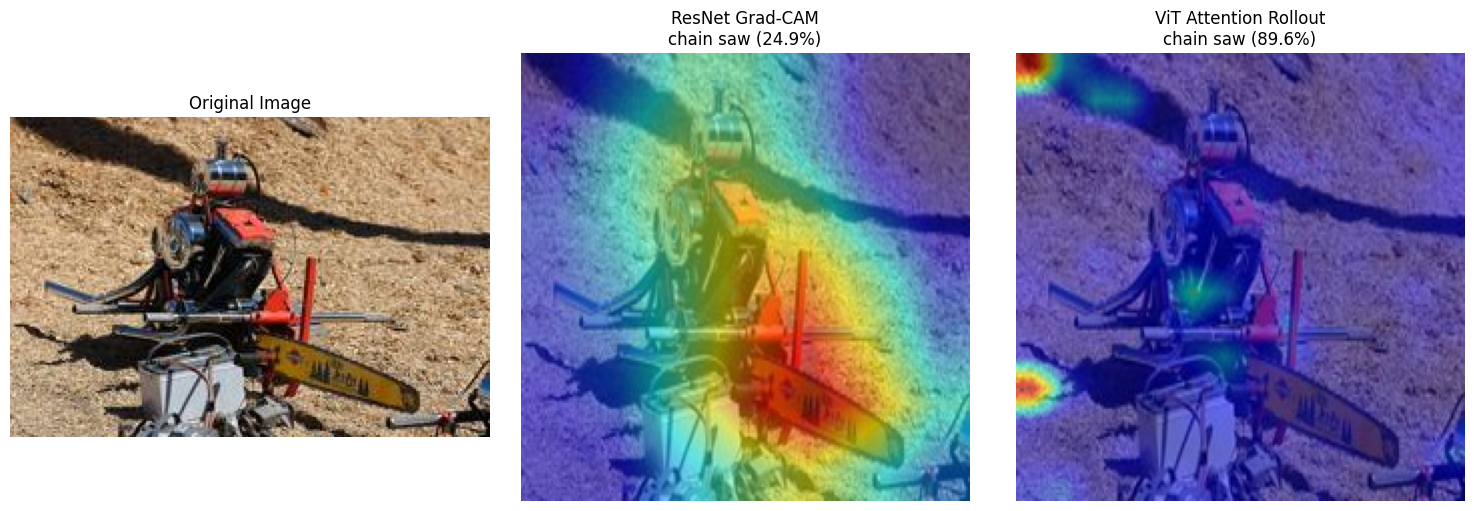


IMAGE 5 OF 10
ImageNette category: Church
ResNet prediction: monastery
ResNet confidence: 86.5%
ViT prediction: monastery
ViT confidence: 84.6%


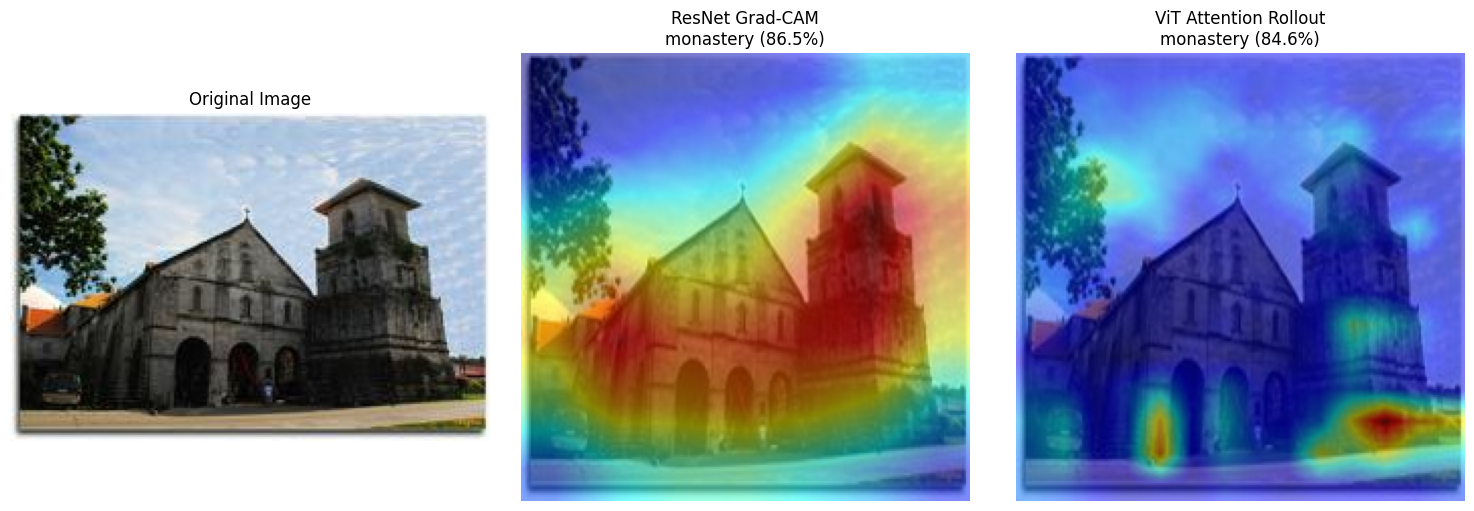


IMAGE 6 OF 10
ImageNette category: French Horn
ResNet prediction: French horn
ResNet confidence: 99.8%
ViT prediction: French horn
ViT confidence: 87.1%


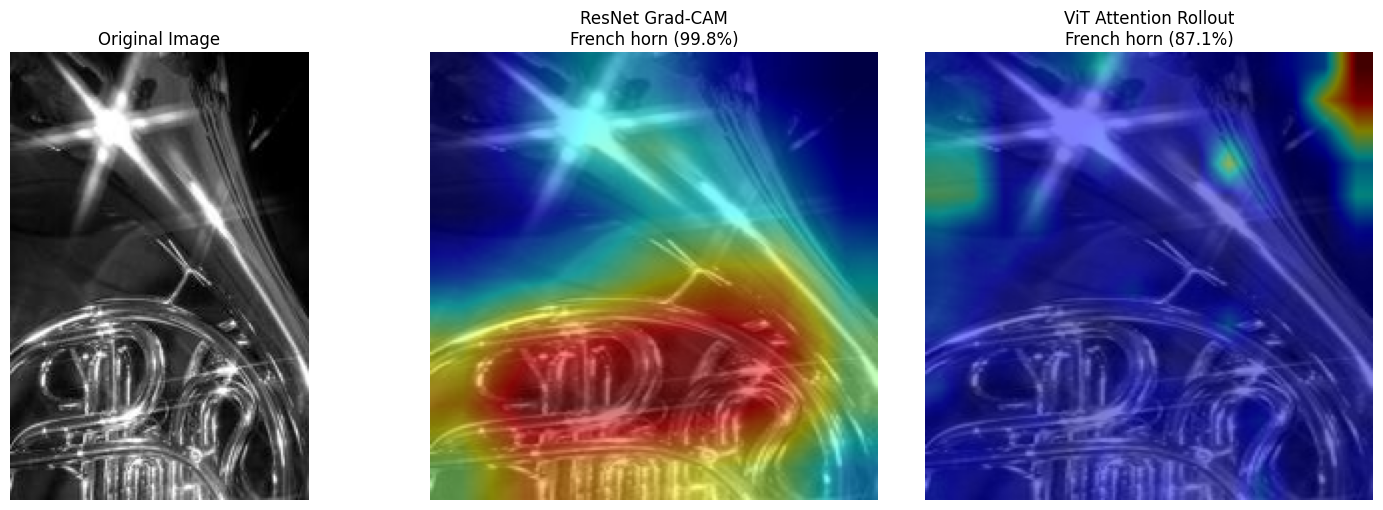


IMAGE 7 OF 10
ImageNette category: Garbage Truck
ResNet prediction: garbage truck
ResNet confidence: 94.7%
ViT prediction: garbage truck
ViT confidence: 90.0%


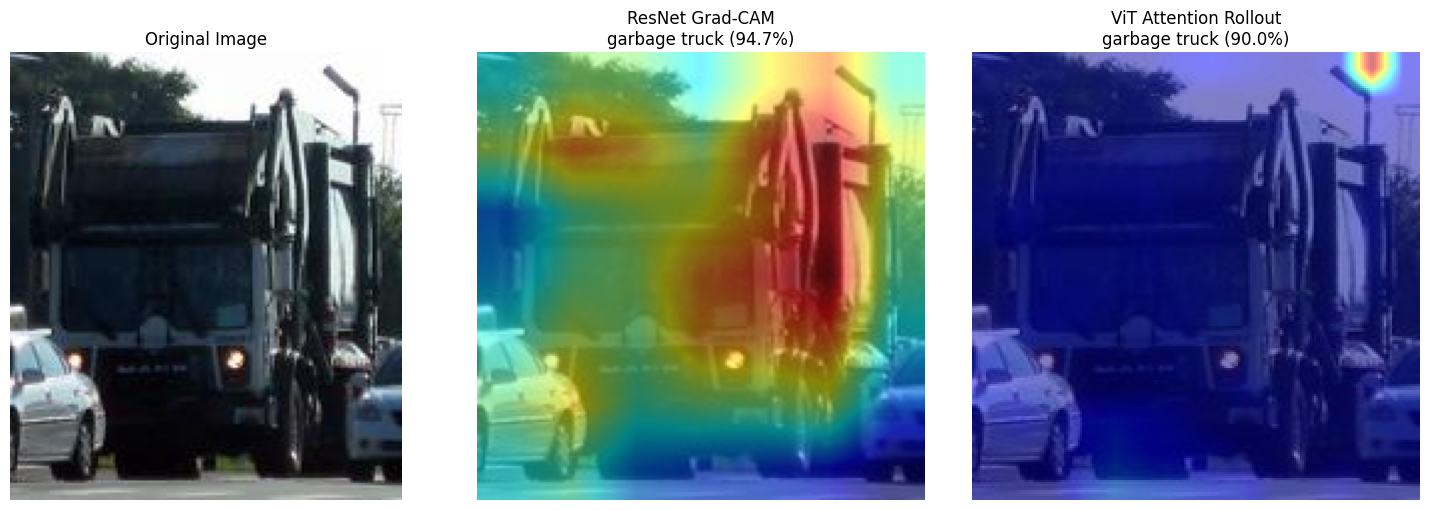


IMAGE 8 OF 10
ImageNette category: Gas Pump
ResNet prediction: thresher
ResNet confidence: 87.5%
ViT prediction: gas pump
ViT confidence: 48.2%


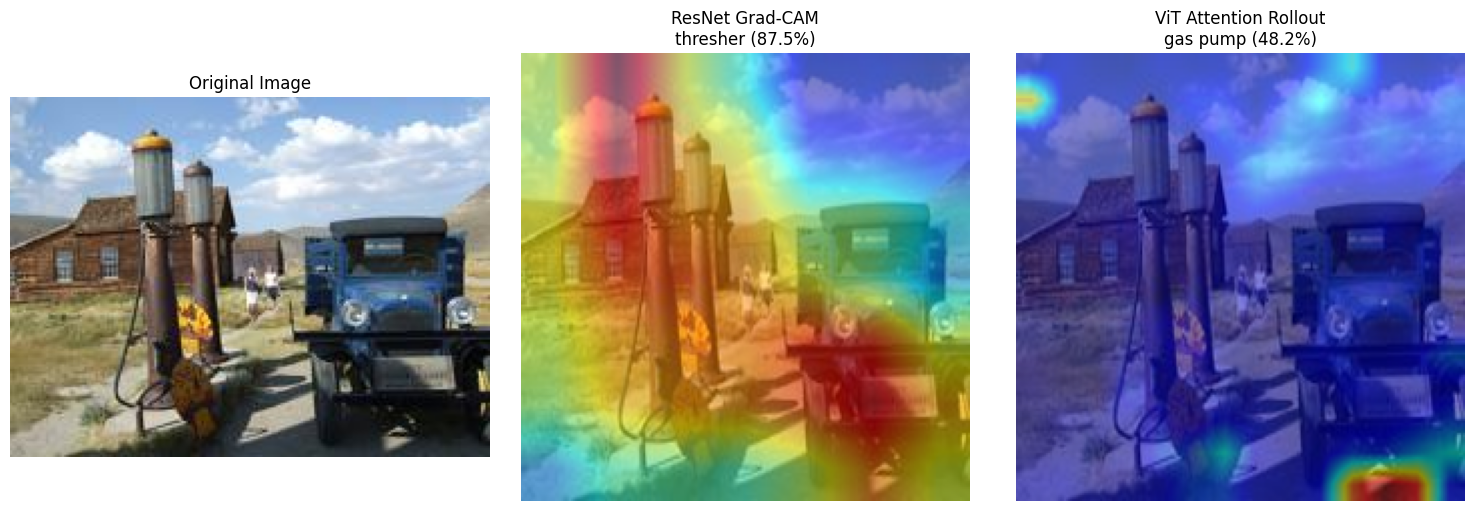


IMAGE 9 OF 10
ImageNette category: Golf Ball
ResNet prediction: golf ball
ResNet confidence: 99.9%
ViT prediction: golf ball
ViT confidence: 87.8%


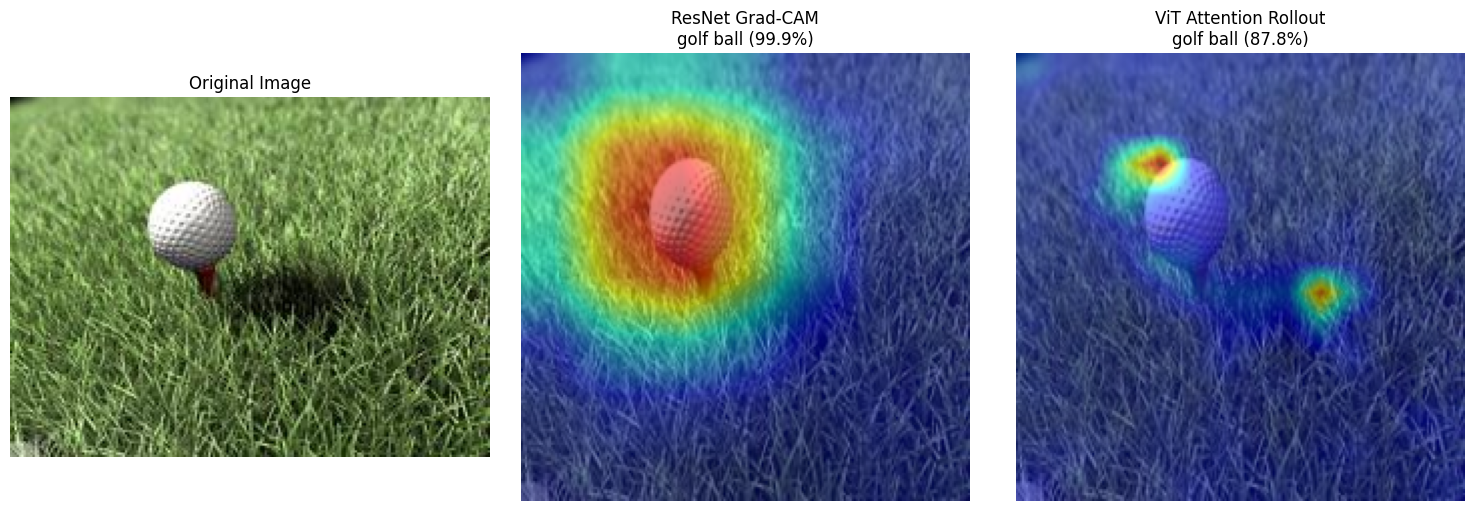


IMAGE 10 OF 10
ImageNette category: Parachute
ResNet prediction: parachute
ResNet confidence: 89.8%
ViT prediction: parachute
ViT confidence: 91.1%


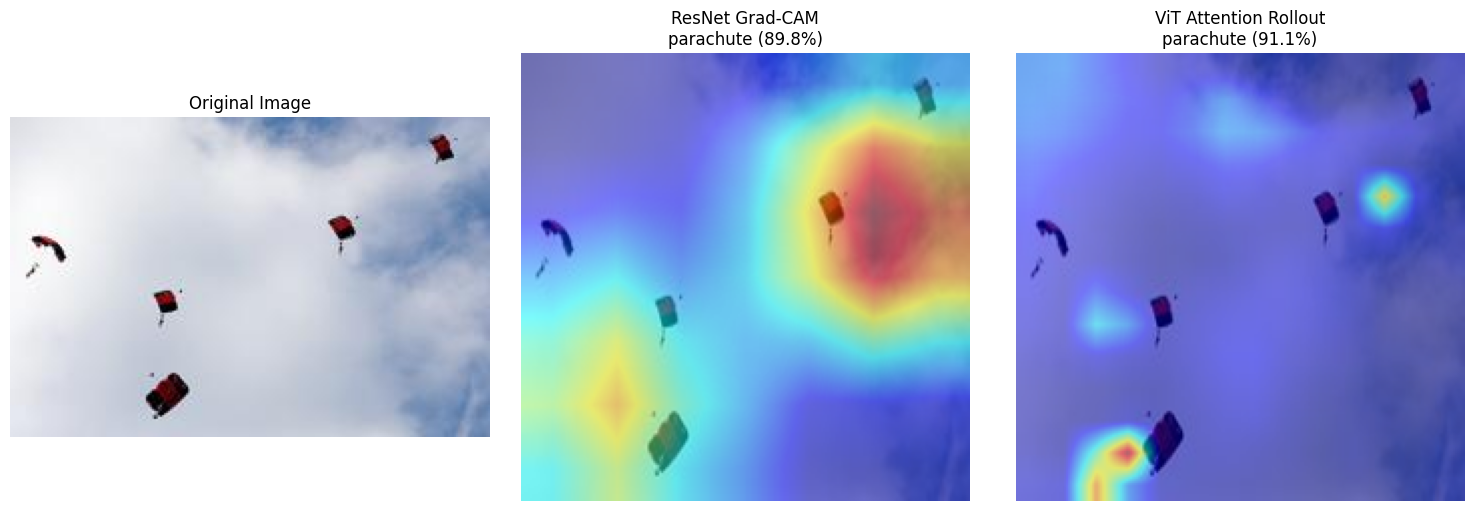


SUMMARY OF ALL 10 IMAGES


,Image,Category,ResNet Prediction,ResNet Confidence,ViT Prediction,ViT Confidence
0,1,Tench,tench,73.3%,tench,82.5%
1,2,English Springer,Cardigan,30.1%,English springer,62.6%
2,3,Cassette Player,tape player,37.3%,CD player,36.2%
3,4,Chain Saw,chain saw,24.9%,chain saw,89.6%
4,5,Church,monastery,86.5%,monastery,84.6%
5,6,French Horn,French horn,99.8%,French horn,87.1%
6,7,Garbage Truck,garbage truck,94.7%,garbage truck,90.0%
7,8,Gas Pump,thresher,87.5%,gas pump,48.2%
8,9,Golf Ball,golf ball,99.9%,golf ball,87.8%
9,10,Parachute,parachute,89.8%,parachute,91.1%


In [7]:
print("=" * 65)
print("GRAD-CAM VS VISION TRANSFORMER RESULTS")
print("=" * 65)

results = []

for i, image_path in enumerate(examples, start=1):
    pil_image = Image.open(image_path).convert("RGB")
    resnet_pred, resnet_conf, gradcam_image = resnet_gradcam(pil_image)
    vit_pred, vit_conf, vit_image = vit_attention_rollout(pil_image)

    category_names = {
        "n01440764": "Tench",
        "n02102040": "English Springer",
        "n02979186": "Cassette Player",
        "n03000684": "Chain Saw",
        "n03028079": "Church",
        "n03394916": "French Horn",
        "n03417042": "Garbage Truck",
        "n03425413": "Gas Pump",
        "n03445777": "Golf Ball",
        "n03888257": "Parachute"
    }

    category = category_names.get(image_path.parent.name, image_path.parent.name)

    # Store results in memory
    results.append({
        "Image": i,
        "Category": category,
        "ResNet Prediction": resnet_pred,
        "ResNet Confidence": f"{resnet_conf * 100:.1f}%",
        "ViT Prediction": vit_pred,
        "ViT Confidence": f"{vit_conf * 100:.1f}%"
    })

    print(f"\n{'=' * 65}")
    print(f"IMAGE {i} OF {len(examples)}")
    print(f"ImageNette category: {category}")
    print(f"ResNet prediction: {resnet_pred}")
    print(f"ResNet confidence: {resnet_conf * 100:.1f}%")
    print(f"ViT prediction: {vit_pred}")
    print(f"ViT confidence: {vit_conf * 100:.1f}%")

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(pil_image)
    axes[0].set_title("Original Image")

    axes[1].imshow(gradcam_image)
    axes[1].set_title(f"ResNet Grad-CAM\n{resnet_pred} ({resnet_conf * 100:.1f}%)")

    axes[2].imshow(vit_image)
    axes[2].set_title(f"ViT Attention Rollout\n{vit_pred} ({vit_conf * 100:.1f}%)")

    for ax in axes:
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    plt.close(fig)

# Summary
import pandas as pd
from IPython.display import display

print("\n" + "=" * 65)
print("SUMMARY OF ALL 10 IMAGES")
print("=" * 65)

display(pd.DataFrame(results))